# Notebook 03 (v2): Dimensionality Reduction, Clustering and Feature Selection
**AID 427 Project Phase 1: MultiCaRe-Fusion**

 Input: the `features` folder from **Notebook 02 v2** (all available blocks are used automatically: ResNet50, DINOv2, BiomedCLIP image embeddings, handcrafted, caption/case TF-IDF (SVD) and BiomedCLIP text embeddings, tabular).
**v2 changes:** bigger candidate pools, true L1 sparsity (`C=0.005`), a lighter GA size penalty (0.0005) with a larger pool (300) and a longer search.

| Part | Methods |
|---|---|
| 1. Fused feature matrix | ResNet50 + handcrafted + caption/case TF-IDF (SVD) + tabular, standardised |
| 2. Linear reduction | PCA, LDA, SVD |
| 3. Non-linear reduction | Kernel PCA, SNE, t-SNE, UMAP, MDS (metric and non-metric), Isomap, LLE |
| 4. Clustering | before vs after reduction (KMeans, Agglomerative, DBSCAN) |
| 5. Feature selection | Filter, Wrapper (forward/backward), Embedded (L1, L2, Elastic Net), Genetic Algorithm and Simulated Annealing |
| 6. Comparison and saved outputs | one table with accuracy, macro-F1, number of features, time |

**Fitting rule:** every scaler, SVD, PCA, LDA and selector is fitted on **training rows only**. The test rows are only transformed, so there is no leakage.

In [1]:
import os, json, time, warnings
import numpy as np, pandas as pd, scipy.sparse as sp
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, TruncatedSVD, KernelPCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import TSNE, MDS, Isomap, LocallyLinearEmbedding, trustworthiness
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.feature_selection import mutual_info_classif, f_classif, SequentialFeatureSelector
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score, accuracy_score, f1_score
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
import umap
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

# ---------------- configuration ----------------
SEED = 42
TARGET = "subtype"        # "subtype" (27 classes, harder) or "type" (7 classes)
N_NONLIN = 3000           # rows used to fit the non-linear embeddings
N_MDS = 800               # rows for SNE and MDS (they are O(n^2))
FS_ROWS = 3000            # rows used to score features in selection
K_POOL_EMBEDDED, K_POOL_WRAPPER, K_POOL_GA = 800, 60, 300      # v2: larger pools (more blocks, more candidates)
rng = np.random.RandomState(SEED); np.random.seed(SEED)

DATA_DIR = next(p for p in ["../DataSet", "DataSet", "."] if os.path.exists(os.path.join(p, "outputs", "features", "index.csv")))
FEAT = os.path.join(DATA_DIR, "outputs", "features"); FIG = os.path.join(DATA_DIR, "outputs", "figures"); RES = os.path.join(DATA_DIR, "outputs", "results")
os.makedirs(FIG, exist_ok=True); os.makedirs(RES, exist_ok=True)
def savefig(name): plt.tight_layout(); plt.savefig(os.path.join(FIG, name), dpi=150, bbox_inches="tight"); plt.show()

## 1. Load features and build the fused matrix

In [2]:
idx = pd.read_csv(os.path.join(FEAT, "index.csv")); classes = json.load(open(os.path.join(FEAT, "classes.json")))
y_type, y_sub = np.load(os.path.join(FEAT, "y_type.npy")), np.load(os.path.join(FEAT, "y_subtype.npy"))
y = y_sub if TARGET == "subtype" else y_type
class_names = classes["image_subtype"] if TARGET == "subtype" else classes["image_type"]
train = (idx.split == "train").values; test = ~train
H  = np.load(os.path.join(FEAT, "img_handcrafted.npy")); T = np.load(os.path.join(FEAT, "tab_features.npy"))
tab_cols = json.load(open(os.path.join(FEAT, "tab_columns.json")))
Xc, Xk = sp.load_npz(os.path.join(FEAT, "text_caption_tfidf.npz")), sp.load_npz(os.path.join(FEAT, "text_case_tfidf.npz"))
n_svd = lambda X: min(200, X.shape[1] - 1)
svd_c = TruncatedSVD(n_svd(Xc), random_state=SEED).fit(Xc[train]); Zc = svd_c.transform(Xc)      # text -> dense (fit on train)
svd_k = TruncatedSVD(n_svd(Xk), random_state=SEED).fit(Xk[train]); Zk = svd_k.transform(Xk)
parts = {}
def load_if(fn):
    p = os.path.join(FEAT, fn); return np.load(p) if os.path.exists(p) else None
for key, fn in [("resnet", "img_resnet50.npy"), ("dinov2", "img_dinov2.npy"), ("biomedclip", "img_biomedclip.npy")]:      # image embeddings (any that exist)
    M_ = load_if(fn)
    if M_ is not None: parts[key] = M_
parts["handcrafted"] = H; parts["caption_svd"] = Zc; parts["case_svd"] = Zk
for key, fn in [("bm_caption", "txt_biomedclip_caption.npy"), ("bm_case", "txt_biomedclip_case.npy")]:                   # BiomedCLIP text embeddings
    M_ = load_if(fn)
    if M_ is not None: parts[key] = M_
parts["tabular"] = T
print("feature blocks found:", {k: v.shape[1] for k, v in parts.items()})
names, block = [], []
for b, M in parts.items():
    names += [f"{b}_{i}" for i in range(M.shape[1])] if b != "tabular" else [f"tab_{c}" for c in tab_cols]
    block += [b] * M.shape[1]
names, block = np.array(names), np.array(block)
X = np.hstack(list(parts.values())).astype(np.float32)
sc = StandardScaler().fit(X[train]); Xs = sc.transform(X).astype(np.float32)                         # per-column standardisation (train stats)
Xs[:, sc.scale_ == 0] = 0
w = np.ones(X.shape[1], dtype=np.float32)
for b in parts: w[block == b] = 1 / np.sqrt((block == b).sum())                                       # each block gets equal total weight
Xw = Xs * w
print("fused matrix:", Xs.shape, "| train", train.sum(), "| test", test.sum(), "| target:", TARGET, f"({len(class_names)} classes)")
print(pd.Series(block).value_counts().to_dict())

feature blocks found: {'resnet': 2048, 'dinov2': 1536, 'biomedclip': 512, 'handcrafted': 347, 'caption_svd': 200, 'case_svd': 200, 'bm_caption': 512, 'bm_case': 512, 'tabular': 11}
fused matrix: (21988, 5878) | train 17673 | test 4315 | target: subtype (27 classes)
{'resnet': 2048, 'dinov2': 1536, 'biomedclip': 512, 'bm_case': 512, 'bm_caption': 512, 'handcrafted': 347, 'caption_svd': 200, 'case_svd': 200, 'tabular': 11}


In [3]:
def knn_acc(Ztr, ytr, Zte, yte, k=10): return KNeighborsClassifier(k, n_jobs=-1).fit(Ztr, ytr).score(Zte, yte)
type_names = classes["image_type"]; pal = sns.color_palette("tab10", len(type_names)); bpal = sns.color_palette("tab10", 10)
def scatter(ax, Z, labels=None, title="", names_=None, s=6):
    labels = y_type if labels is None else labels; names_ = names_ or type_names
    for c in np.unique(labels): ax.scatter(*Z[labels == c, :2].T, s=s, color=pal[c % len(pal)], label=names_[c], alpha=0.7)
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
print("baseline kNN accuracy on ALL fused features (no reduction):", round(knn_acc(Xw[train], y[train], Xw[test], y[test]), 3))

baseline kNN accuracy on ALL fused features (no reduction): 0.763


## 2. Linear feature reduction: PCA, LDA, SVD

### 2.1 PCA

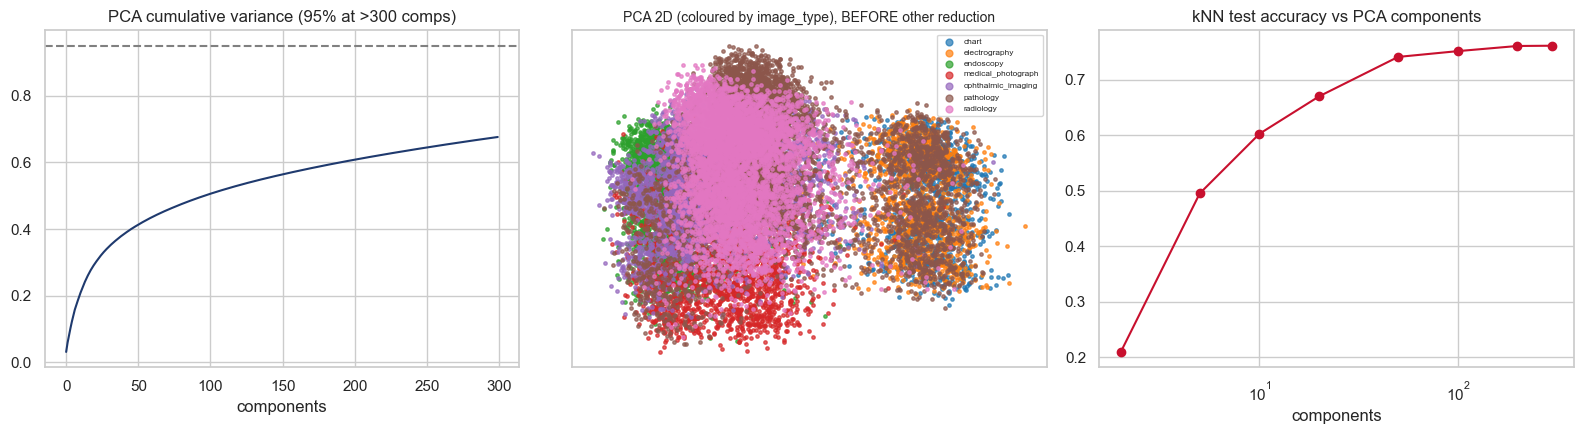

PCA: 90% variance at >300 comps, 95% at >300 | fit 11.2s | acc by k: {2: np.float64(0.21), 5: np.float64(0.495), 10: np.float64(0.603), 20: np.float64(0.67), 50: np.float64(0.741), 100: np.float64(0.751), 200: np.float64(0.761), 300: np.float64(0.761)}


In [4]:
t0 = time.time(); pca = PCA(n_components=min(300, Xw.shape[1], train.sum() - 1), random_state=SEED).fit(Xw[train]); t_pca = time.time() - t0
ev = np.cumsum(pca.explained_variance_ratio_); n90, n95 = [(int(np.searchsorted(ev, q)) + 1 if ev[-1] >= q else f">{len(ev)}") for q in (0.90, 0.95)]
Zp = pca.transform(Xw)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].plot(ev, color="#1F3A6E"); ax[0].axhline(0.95, ls="--", c="grey"); ax[0].set_title(f"PCA cumulative variance (95% at {n95} comps)"); ax[0].set_xlabel("components")
scatter(ax[1], Zp, y_type, "PCA 2D (coloured by image_type), BEFORE other reduction"); ax[1].legend(fontsize=6, markerscale=2)
ks = [k for k in [2, 5, 10, 20, 50, 100, 200, 300] if k <= Zp.shape[1]]; acc_pca = [knn_acc(Zp[train][:, :k], y[train], Zp[test][:, :k], y[test]) for k in ks]
ax[2].plot(ks, acc_pca, "o-", color="#C8102E"); ax[2].set_xscale("log"); ax[2].set_title("kNN test accuracy vs PCA components"); ax[2].set_xlabel("components")
savefig("10_pca.png"); print(f"PCA: 90% variance at {n90} comps, 95% at {n95} | fit {t_pca:.1f}s | acc by k:", dict(zip(ks, np.round(acc_pca, 3))))

### 2.2 LDA (supervised, at most classes-1 components)

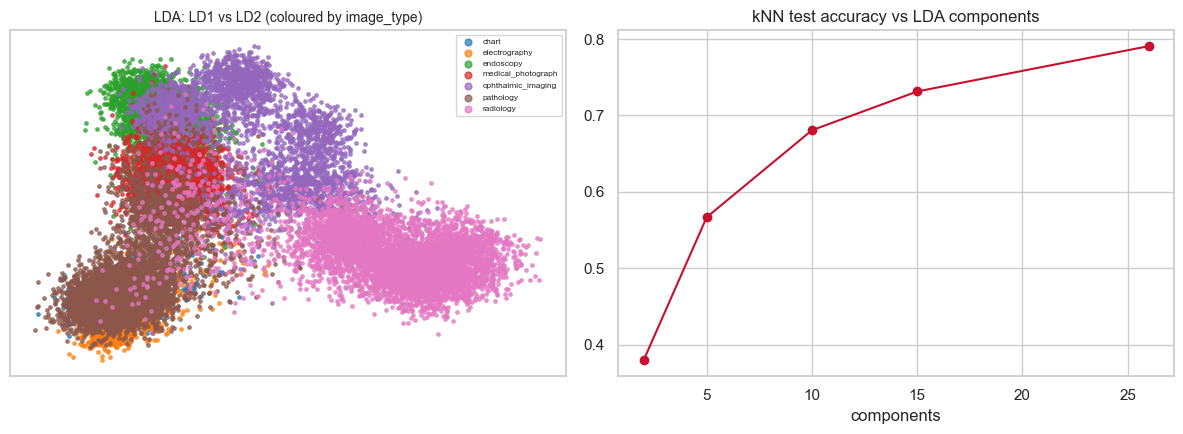

LDA components: 26 | fit 1.0s | acc: {2: np.float64(0.379), 5: np.float64(0.567), 10: np.float64(0.681), 15: np.float64(0.731), 26: np.float64(0.791)}


In [5]:
pca_l = PCA(min(200, Xw.shape[1], train.sum() - 1), random_state=SEED).fit(Xw[train])               # LDA on PCA space avoids singular covariances
t0 = time.time(); lda = LinearDiscriminantAnalysis(n_components=min(len(class_names) - 1, 26)).fit(pca_l.transform(Xw[train]), y[train]); t_lda = time.time() - t0
Zl = lda.transform(pca_l.transform(Xw))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5)); scatter(ax[0], Zl, y_type, "LDA: LD1 vs LD2 (coloured by image_type)"); ax[0].legend(fontsize=6, markerscale=2)
kl = [k for k in [2, 5, 10, 15, 26] if k <= Zl.shape[1]]; acc_lda = [knn_acc(Zl[train][:, :k], y[train], Zl[test][:, :k], y[test]) for k in kl]
ax[1].plot(kl, acc_lda, "o-", color="#C8102E"); ax[1].set_title("kNN test accuracy vs LDA components"); ax[1].set_xlabel("components"); savefig("11_lda.png")
print(f"LDA components: {Zl.shape[1]} | fit {t_lda:.1f}s | acc:", dict(zip(kl, np.round(acc_lda, 3))))

### 2.3 SVD (truncated, no centering) compared with PCA

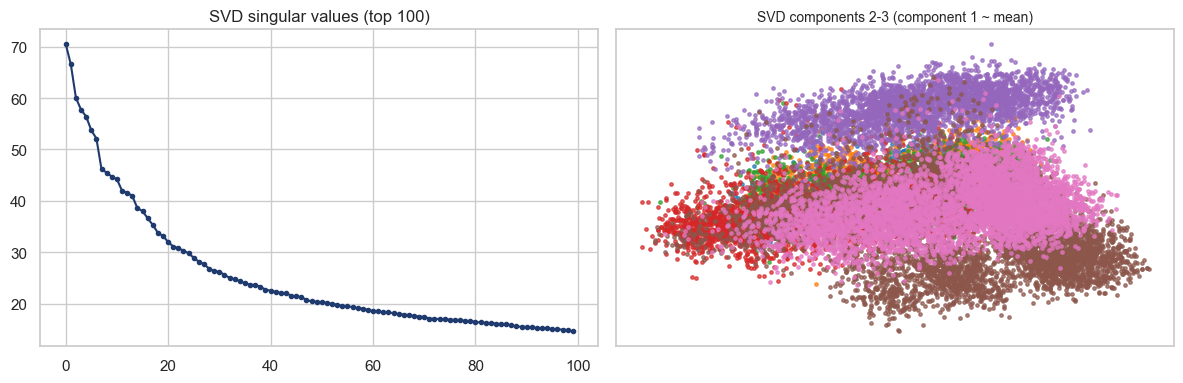

SVD(100): kNN acc 0.751 vs PCA(100): 0.751 | fit 3.5s
Note: our data is standardised (mean 0), so SVD and PCA give almost the same subspace.


In [6]:
t0 = time.time(); svd = TruncatedSVD(100, random_state=SEED).fit(Xw[train]); t_svd = time.time() - t0; Zs_svd = svd.transform(Xw)
fig, ax = plt.subplots(1, 2, figsize=(12, 4)); ax[0].plot(svd.singular_values_, "o-", ms=3, color="#1F3A6E"); ax[0].set_title("SVD singular values (top 100)")
scatter(ax[1], Zs_svd[:, 1:], y_type, "SVD components 2-3 (component 1 ~ mean)"); savefig("12_svd.png")
print(f"SVD(100): kNN acc {knn_acc(Zs_svd[train], y[train], Zs_svd[test], y[test]):.3f} vs PCA(100): {knn_acc(Zp[train][:, :100], y[train], Zp[test][:, :100], y[test]):.3f} | fit {t_svd:.1f}s")
print("Note: our data is standardised (mean 0), so SVD and PCA give almost the same subspace.")

## 3. Non-linear feature reduction

Non-linear methods are O(n^2) or worse, so they are fitted on a **stratified sample of training rows** after a PCA-50 step (standard practice, also removes noise). Methods with a `transform` (Kernel PCA, UMAP, Isomap, LLE) are also applied to the test rows. t-SNE, SNE and MDS only give an embedding of the points they were fitted on (visualisation / clustering).

In [7]:
def sne(Xin, perplexity=30, n_iter=300, lr=0.5, seed=0):
    '''Vanilla (asymmetric) Stochastic Neighbour Embedding in numpy: Gaussian P rows, softmax Q, gradient descent with momentum.'''
    n = Xin.shape[0]; D = euclidean_distances(Xin, squared=True); D /= np.median(D)
    P = np.zeros((n, n)); target = np.log(perplexity)
    for i in range(n):
        Di = np.delete(D[i], i); Di = Di - Di.min(); lo, hi, beta = 0.0, np.inf, 1.0
        for _ in range(60):
            Pi = np.exp(-Di * beta); sP = Pi.sum(); Hh = np.log(sP) + beta * (Di * Pi).sum() / sP
            if abs(Hh - target) < 1e-4: break
            if Hh > target: lo = beta; beta = beta * 2 if hi == np.inf else (beta + hi) / 2
            else: hi = beta; beta = beta / 2 if lo == 0 else (beta + lo) / 2
        P[i, np.arange(n) != i] = Pi / sP
    Y = PCA(2, random_state=seed).fit_transform(Xin); Y = Y / Y.std() * 0.5; V = np.zeros_like(Y)
    for it in range(n_iter):
        d2 = euclidean_distances(Y, squared=True); Q = np.exp(-d2); np.fill_diagonal(Q, 0); Q /= Q.sum(1, keepdims=True) + 1e-12
        M = (P - Q) + (P - Q).T; G = 2 * (M.sum(1)[:, None] * Y - M @ Y)
        G = np.clip(G, -5, 5); V = (0.5 if it < 100 else 0.8) * V - lr * G; Y = Y + V
    return Y

samp, _ = train_test_split(np.where(train)[0], train_size=min(N_NONLIN, int(train.sum() * 0.8)), stratify=y[train], random_state=SEED)
pca50 = PCA(min(50, Xw.shape[1]), random_state=SEED).fit(Xw[train]); Zs, Zt = pca50.transform(Xw[samp]), pca50.transform(Xw[test])
ys, yts, ysty = y[samp], y[test], y_type[samp]
m = min(N_MDS, len(samp)); print("sample:", len(samp), "| SNE/MDS subset:", m, "| input dims:", Zs.shape[1])

sample: 3000 | SNE/MDS subset: 800 | input dims: 50


In [8]:
emb, rows = {}, []
def run(name, fit, n=None, transform=None):
    n = n or len(samp); t0 = time.time()
    try:
        Y = fit(Zs[:n]); dt = time.time() - t0
        tw = trustworthiness(Zs[:n], Y, n_neighbors=10); kc = cross_val_score(KNeighborsClassifier(10), Y, ys[:n], cv=5).mean(); sil = silhouette_score(Y, ys[:n])
        ta = np.nan
        if transform is not None: ta = knn_acc(Y, ys[:n], transform(Zt), yts)
        emb[name] = (Y, ysty[:n]); rows.append([name, n, round(dt, 1), round(tw, 3), round(kc, 3), round(sil, 3), round(ta, 3) if ta == ta else np.nan])
        print(f"{name:14s} n={n:5d} time={dt:6.1f}s trust={tw:.3f} knn-cv={kc:.3f} silhouette={sil:.3f}")
    except Exception as e: print(name, "FAILED:", repr(e)[:150])

gamma = 1.0 / (Zs.shape[1] * Zs.var()); kpca = KernelPCA(2, kernel="rbf", gamma=gamma, random_state=SEED); run("KernelPCA", kpca.fit_transform, transform=lambda Z: kpca.transform(Z))
run("SNE", lambda Z: sne(Z, seed=SEED), n=m)
run("t-SNE", lambda Z: TSNE(2, perplexity=30, init="pca", random_state=SEED).fit_transform(Z))
um = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED); run("UMAP", um.fit_transform, transform=lambda Z: um.transform(Z))
run("MDS (metric)", lambda Z: MDS(2, n_init=1, max_iter=200, random_state=SEED).fit_transform(Z), n=m)
run("MDS (non-metric)", lambda Z: MDS(2, metric=False, n_init=1, max_iter=200, random_state=SEED).fit_transform(Z), n=m)
iso = Isomap(n_neighbors=15, n_components=2); run("Isomap", iso.fit_transform, transform=lambda Z: iso.transform(Z))
lle = LocallyLinearEmbedding(n_neighbors=15, n_components=2, random_state=SEED); run("LLE", lle.fit_transform, transform=lambda Z: lle.transform(Z))
res_nl = pd.DataFrame(rows, columns=["method", "n_points", "time_s", "trustworthiness", "kNN_cv_acc", "silhouette", "kNN_test_acc (transform)"])
res_nl.to_csv(os.path.join(RES, "nonlinear_reduction.csv"), index=False); res_nl

KernelPCA      n= 3000 time=   0.3s trust=0.733 knn-cv=0.238 silhouette=-0.201
SNE            n=  800 time=   9.0s trust=0.880 knn-cv=0.432 silhouette=-0.123
t-SNE          n= 3000 time=  15.1s trust=0.991 knn-cv=0.623 silhouette=-0.079
UMAP           n= 3000 time=  30.0s trust=0.988 knn-cv=0.606 silhouette=-0.158
MDS (metric)   n=  800 time=   5.0s trust=0.773 knn-cv=0.292 silhouette=-0.212
MDS (non-metric) n=  800 time=  45.2s trust=0.779 knn-cv=0.211 silhouette=-0.206
Isomap         n= 3000 time=   6.8s trust=0.734 knn-cv=0.246 silhouette=-0.210
LLE            n= 3000 time=   2.5s trust=0.770 knn-cv=0.340 silhouette=-0.189


,method,n_points,time_s,trustworthiness,kNN_cv_acc,silhouette,kNN_test_acc (transform)
0,KernelPCA,3000,0.3,0.733,0.238,-0.201,0.254
1,SNE,800,9.0,0.880,0.432,-0.123,NaN
2,t-SNE,3000,15.1,0.991,0.623,-0.079,NaN
3,UMAP,3000,30.0,0.988,0.606,-0.158,0.596
4,MDS (metric),800,5.0,0.773,0.292,-0.212,NaN
5,MDS (non-metric),800,45.2,0.779,0.211,-0.206,NaN
6,Isomap,3000,6.8,0.734,0.246,-0.210,0.266
7,LLE,3000,2.5,0.770,0.340,-0.189,0.359


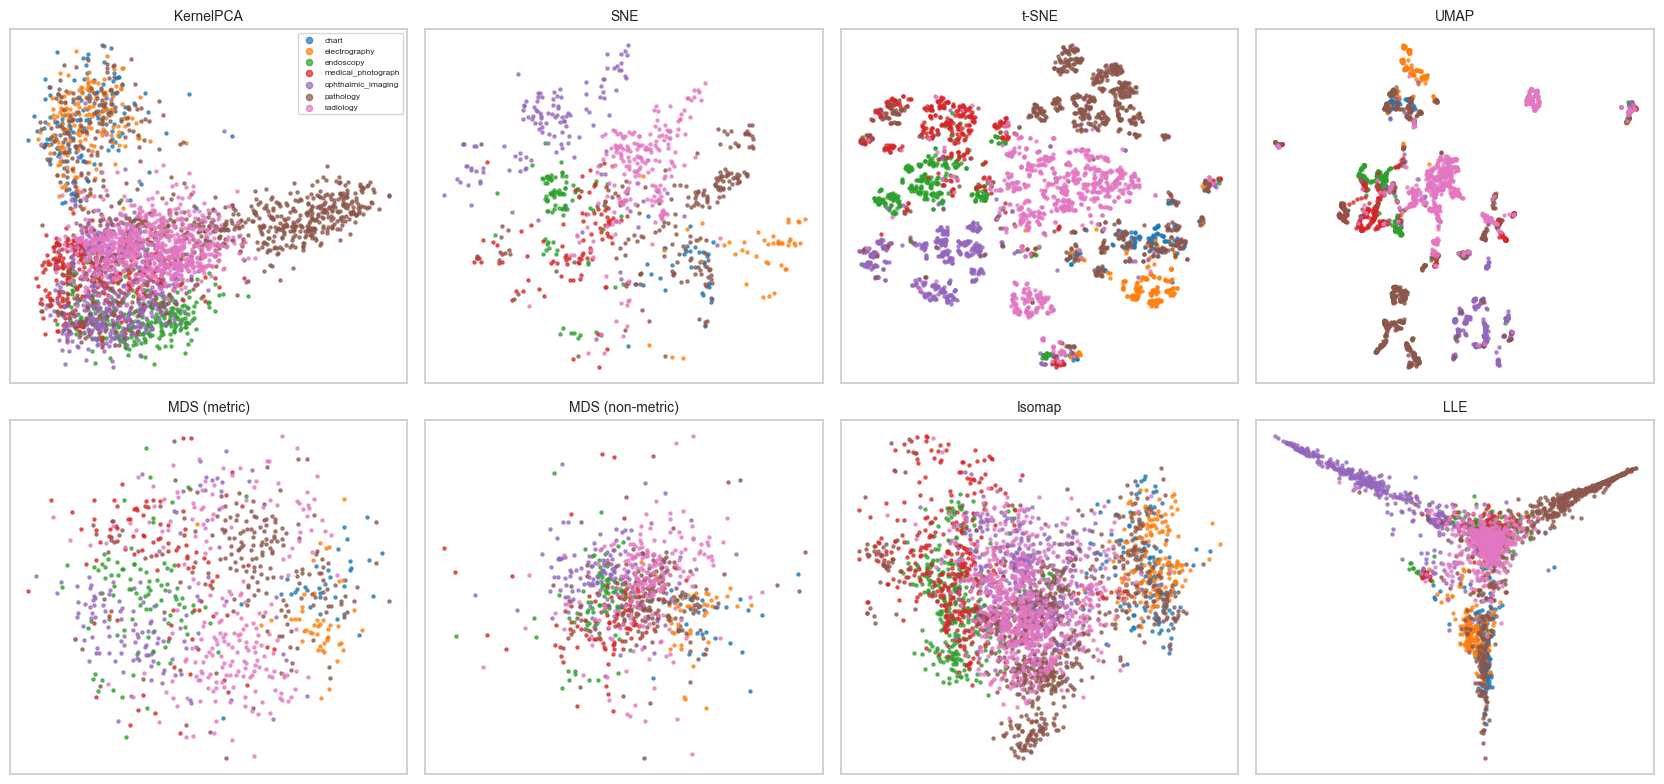

In [9]:
k = len(emb); cols = 4; rws = int(np.ceil(k / cols))
fig, axes = plt.subplots(rws, cols, figsize=(4.2 * cols, 4 * rws)); axes = np.array(axes).ravel()
for a, (nm, (Y, lab)) in zip(axes, emb.items()): scatter(a, Y, lab, nm, s=5)
for a in axes[k:]: a.axis("off")
axes[0].legend(fontsize=6, markerscale=2); savefig("13_nonlinear_embeddings.png")

## 4. Clustering: before vs after reduction
Clusters are computed in the **high-dimensional PCA-50 space (before)** and in **UMAP-10 / LDA spaces (after)**, then compared with the real classes (ARI, NMI) and by silhouette. Plots use the same 2D UMAP view, coloured by true class and by cluster.

In [10]:
u10 = umap.UMAP(n_neighbors=15, min_dist=0.0, n_components=10, random_state=SEED).fit(Zs); Z_u10 = u10.embedding_
Z_lda_s = lda.transform(pca_l.transform(Xw[samp]))
spaces = {"before: PCA-50": Zs, "after: UMAP-10": Z_u10, "after: LDA": Z_lda_s}
def eps_for(Z, k=10): return float(np.percentile(NearestNeighbors(n_neighbors=k).fit(Z).kneighbors(Z)[0][:, -1], 60))
rows, labs = [], {}
for sn, Z in spaces.items():
    algos = {"KMeans": KMeans(len(class_names), n_init=5, random_state=SEED).fit_predict(Z),
             "Agglomerative": AgglomerativeClustering(len(class_names), linkage="ward").fit_predict(Z),
             "DBSCAN": DBSCAN(eps=eps_for(Z), min_samples=10).fit_predict(Z)}
    for an, lb in algos.items():
        ncl = len(set(lb)) - (1 if -1 in lb else 0); sil = silhouette_score(Z, lb) if ncl > 1 else np.nan
        rows.append([sn, an, ncl, round(adjusted_rand_score(ys, lb), 3), round(normalized_mutual_info_score(ys, lb), 3), round(sil, 3) if sil == sil else np.nan]); labs[(sn, an)] = lb
res_cl = pd.DataFrame(rows, columns=["space", "algorithm", "n_clusters", "ARI", "NMI", "silhouette"]); res_cl.to_csv(os.path.join(RES, "clustering.csv"), index=False); res_cl

,space,algorithm,n_clusters,ARI,NMI,silhouette
0,before: PCA-50,KMeans,27,0.322,0.510,0.111
1,before: PCA-50,Agglomerative,27,0.285,0.485,0.101
2,before: PCA-50,DBSCAN,12,0.008,0.115,-0.033
3,after: UMAP-10,KMeans,27,0.268,0.475,0.624
4,after: UMAP-10,Agglomerative,27,0.259,0.470,0.622
5,after: UMAP-10,DBSCAN,94,0.062,0.464,0.282
6,after: LDA,KMeans,27,0.598,0.733,0.332
7,after: LDA,Agglomerative,27,0.559,0.719,0.328
8,after: LDA,DBSCAN,18,0.279,0.623,0.221


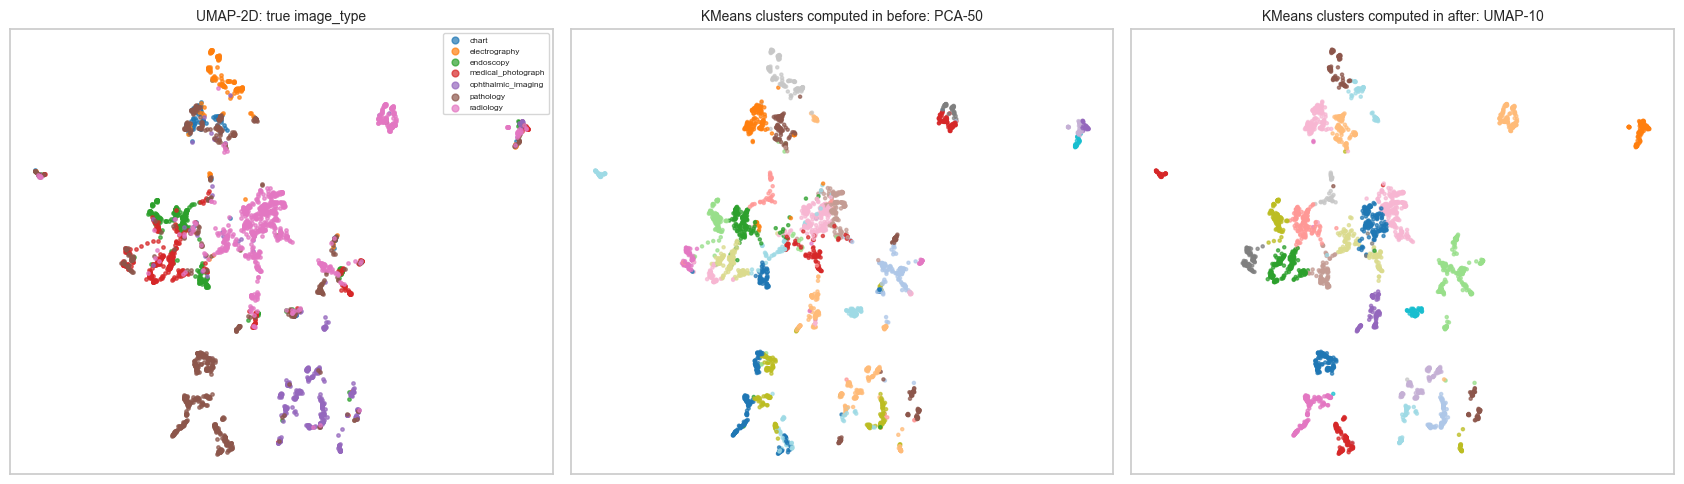

In [11]:
Y2 = emb["UMAP"][0] if "UMAP" in emb else Zs[:, :2]
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
scatter(ax[0], Y2, ysty, "UMAP-2D: true image_type"); ax[0].legend(fontsize=6, markerscale=2)
for a, key in zip(ax[1:], [("before: PCA-50", "KMeans"), ("after: UMAP-10", "KMeans")]):
    a.scatter(*Y2.T, c=labs[key], s=5, cmap="tab20", alpha=0.7); a.set_title(f"KMeans clusters computed in {key[0]}", fontsize=10); a.set_xticks([]); a.set_yticks([])
savefig("14_clustering_before_after.png")

## 5. Feature selection
Scoring uses a stratified sample of the training rows (`FS_ROWS`). The final accuracy of each selected set is measured by training on **all** training rows and testing on the untouched test rows. A fast shrinkage-LDA is the wrapper/GA estimator; Logistic Regression is the final classifier.

In [12]:
fs_idx, _ = train_test_split(np.where(train)[0], train_size=min(FS_ROWS, int(train.sum() * 0.8)), stratify=y[train], random_state=SEED)
Xf, yf = Xs[fs_idx], y[fs_idx]
est = lambda: LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")
cv3 = StratifiedKFold(3, shuffle=True, random_state=SEED)
def final_eval(cols):
    t0 = time.time(); sc_ = StandardScaler().fit(Xs[train][:, cols]); clf = LogisticRegression(max_iter=300).fit(sc_.transform(Xs[train][:, cols]), y[train])
    p = clf.predict(sc_.transform(Xs[test][:, cols])); return accuracy_score(y[test], p), f1_score(y[test], p, average="macro"), time.time() - t0
sel, results = {}, []
def record(method, cols, fs_time):
    acc, f1, _ = final_eval(np.array(cols)); sel[method] = [int(c) for c in cols]
    results.append([method, len(cols), round(acc, 4), round(f1, 4), round(fs_time, 1)]); print(f"{method:28s} features={len(cols):5d} acc={acc:.3f} macroF1={f1:.3f} select-time={fs_time:.0f}s")
all_cols = np.arange(Xs.shape[1]); acc, f1, _ = final_eval(all_cols)
results.append(["Baseline: all features", len(all_cols), round(acc, 4), round(f1, 4), 0.0]); print(f"all features {len(all_cols)}: acc={acc:.3f} macroF1={f1:.3f}")

all features 5878: acc=0.794 macroF1=0.784


### 5.1 Filter methods (variance, correlation, ANOVA F, mutual information)

features: 5878 -> variance filter 5878 -> correlation filter 5870
filter time: 65s


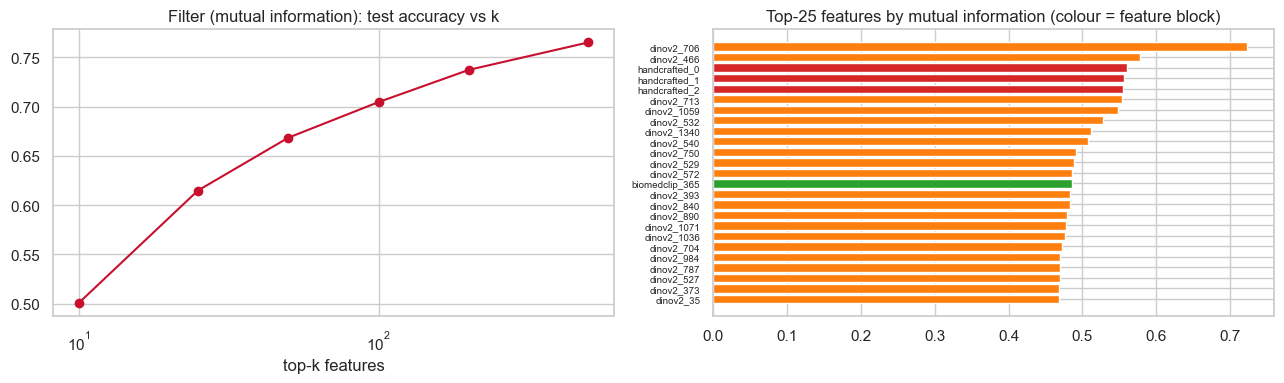

Filter MI top-50             features=   50 acc=0.702 macroF1=0.674 select-time=65s
Filter MI top-100            features=  100 acc=0.732 macroF1=0.710 select-time=65s
Filter ANOVA-F top-100       features=  100 acc=0.738 macroF1=0.716 select-time=65s


In [13]:
t0 = time.time()
var_ok = np.where(Xf.var(0) > 1e-8)[0]                                                           # 1) variance filter
corr = np.corrcoef(Xf[:, var_ok].T); keep = []                                                    # 2) drop one of each |r| > 0.95 pair
dropped = np.zeros(len(var_ok), bool)
for i in range(len(var_ok)):
    if dropped[i]: continue
    keep.append(i); dropped[(np.abs(corr[i]) > 0.95) & (np.arange(len(var_ok)) > i)] = True
cand = var_ok[keep]
print(f"features: {Xs.shape[1]} -> variance filter {len(var_ok)} -> correlation filter {len(cand)}")
Fv, _ = f_classif(Xf[:, cand], yf); Fv = np.nan_to_num(Fv)                                        # 3) ANOVA F
MI = np.zeros(Xs.shape[1]); MI[cand] = mutual_info_classif(Xf[:, cand], yf, random_state=SEED, n_jobs=-1)   # 4) mutual information
rank_mi = cand[np.argsort(-MI[cand])]; t_filter = time.time() - t0
print("filter time: %.0fs" % t_filter)
ks_f = [k for k in [10, 25, 50, 100, 200, 500] if k <= len(rank_mi)]
curve = [accuracy_score(y[test], est().fit(Xs[train][:, rank_mi[:k]], y[train]).predict(Xs[test][:, rank_mi[:k]])) for k in ks_f]
fig, ax = plt.subplots(1, 2, figsize=(13, 4)); ax[0].plot(ks_f, curve, "o-", color="#C8102E"); ax[0].set_xscale("log"); ax[0].set_title("Filter (mutual information): test accuracy vs k"); ax[0].set_xlabel("top-k features")
top = rank_mi[:25]; ax[1].barh(range(25)[::-1], MI[top], color=[bpal[list(parts).index(b)] for b in block[top]]); ax[1].set_yticks(range(25)[::-1]); ax[1].set_yticklabels(names[top], fontsize=7); ax[1].set_title("Top-25 features by mutual information (colour = feature block)")
savefig("15_filter_methods.png")
for k in [50, 100]:
    if k <= len(rank_mi): record(f"Filter MI top-{k}", rank_mi[:k], t_filter)
Fsel = cand[np.argsort(-Fv)][:100]; record("Filter ANOVA-F top-100", Fsel, t_filter)

### 5.2 Embedded methods (L1, L2, Elastic Net)

In [14]:
pool = rank_mi[:K_POOL_EMBEDDED]; Xp, Xp_full = Xf[:, pool], Xs[:, pool]
def embedded(name, **kw):
    t0 = time.time(); lr_ = LogisticRegression(solver="saga", max_iter=150, tol=1e-3, **kw).fit(Xp, yf)
    imp = np.abs(lr_.coef_).max(0); nz = int((imp > 1e-6).sum())
    cols = pool[np.argsort(-imp)[:100]] if nz > 100 or name == "Embedded L2 (ridge)" else pool[imp > 1e-6]
    record(name, cols, time.time() - t0); return imp
imp_l1 = embedded("Embedded L1 (lasso)", penalty="l1", C=0.005)
imp_l2 = embedded("Embedded L2 (ridge)", penalty="l2", C=0.05)
imp_en = embedded("Embedded ElasticNet", penalty="elasticnet", l1_ratio=0.5, C=0.05)
print("non-zero coefficients in the pool of", len(pool), ": L1 =", int((imp_l1 > 1e-6).sum()), "| ElasticNet =", int((imp_en > 1e-6).sum()), "| L2 =", int((imp_l2 > 1e-6).sum()), "(L2 does not zero out; top-100 by |coef| used)")

Embedded L1 (lasso)          features=   31 acc=0.692 macroF1=0.657 select-time=25s
Embedded L2 (ridge)          features=  100 acc=0.775 macroF1=0.757 select-time=39s
Embedded ElasticNet          features=  100 acc=0.772 macroF1=0.753 select-time=88s
non-zero coefficients in the pool of 800 : L1 = 31 | ElasticNet = 634 | L2 = 800 (L2 does not zero out; top-100 by |coef| used)


### 5.3 Wrapper methods (forward and backward selection)

In [15]:
pw = rank_mi[:K_POOL_WRAPPER]; n_sel = min(20, len(pw) - 1)
for direction in ["forward", "backward"]:
    t0 = time.time(); sfs = SequentialFeatureSelector(est(), n_features_to_select=n_sel, direction=direction, cv=cv3, scoring="accuracy", n_jobs=-1).fit(Xf[:, pw], yf)
    record(f"Wrapper {direction} SFS", pw[sfs.get_support()], time.time() - t0)

Wrapper forward SFS          features=   20 acc=0.645 macroF1=0.611 select-time=68s
Wrapper backward SFS         features=   20 acc=0.657 macroF1=0.625 select-time=127s


### 5.4 Metaheuristics: Genetic Algorithm and Simulated Annealing

Genetic Algorithm            features=   86 acc=0.741 macroF1=0.719 select-time=109s
Simulated Annealing          features=   89 acc=0.740 macroF1=0.719 select-time=101s


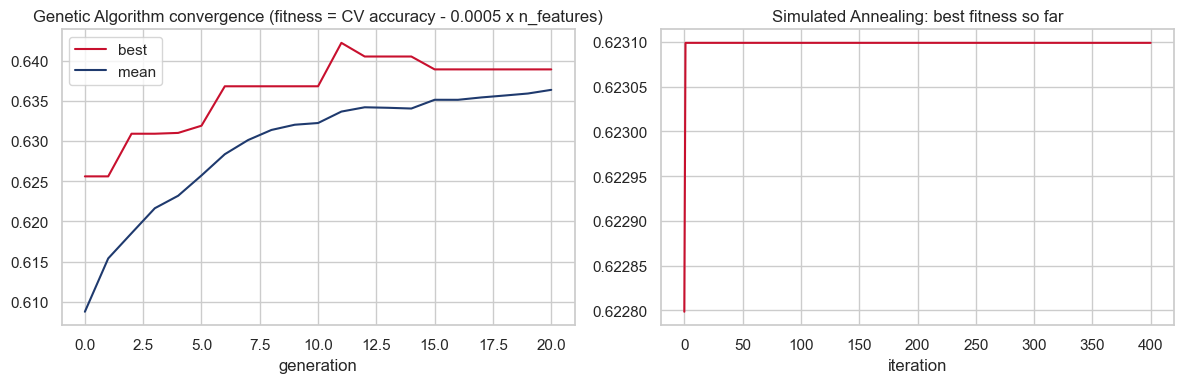

In [16]:
from deap import base, creator, tools, algorithms
import random
random.seed(SEED); pg = rank_mi[:K_POOL_GA]; ga_rows = min(2500, len(fs_idx)); Xg, yg = Xf[:ga_rows][:, pg], yf[:ga_rows]; LAMBDA = 0.0005
cache = {}
def fitness_mask(mask):
    key = tuple(mask)
    if key not in cache:
        if sum(mask) == 0: cache[key] = (-1.0,)
        else: cache[key] = (cross_val_score(est(), Xg[:, np.array(mask, bool)], yg, cv=cv3, scoring="accuracy").mean() - LAMBDA * sum(mask),)
    return cache[key]
creator.create("FitMax", base.Fitness, weights=(1.0,)); creator.create("Ind", list, fitness=creator.FitMax)
tb = base.Toolbox(); tb.register("bit", lambda: int(random.random() < 0.3)); tb.register("ind", tools.initRepeat, creator.Ind, tb.bit, n=len(pg)); tb.register("pop", tools.initRepeat, list, tb.ind)
tb.register("evaluate", fitness_mask); tb.register("mate", tools.cxTwoPoint); tb.register("mutate", tools.mutFlipBit, indpb=0.02); tb.register("select", tools.selTournament, tournsize=3)
pop = tb.pop(n=40); hof = tools.HallOfFame(1); stats = tools.Statistics(lambda i: i.fitness.values[0]); stats.register("max", np.max); stats.register("mean", np.mean)
t0 = time.time(); pop, log = algorithms.eaSimple(pop, tb, cxpb=0.7, mutpb=0.3, ngen=20, stats=stats, halloffame=hof, verbose=False); t_ga = time.time() - t0
record("Genetic Algorithm", pg[np.array(hof[0], bool)], t_ga)

def simulated_annealing(n_iter=400, T0=0.02):
    cur = [int(random.random() < 0.3) for _ in pg]; fc = fitness_mask(cur)[0]; best, fb = cur[:], fc; hist = [fb]
    for it in range(n_iter):
        T = T0 * (1 - it / n_iter) + 1e-6; cand_ = cur[:]; j = random.randrange(len(pg)); cand_[j] ^= 1; fn = fitness_mask(cand_)[0]
        if fn > fc or random.random() < np.exp((fn - fc) / T): cur, fc = cand_, fn
        if fc > fb: best, fb = cur[:], fc
        hist.append(fb)
    return best, hist
t0 = time.time(); best_sa, hist_sa = simulated_annealing(); record("Simulated Annealing", pg[np.array(best_sa, bool)], time.time() - t0)
fig, ax = plt.subplots(1, 2, figsize=(12, 4)); ax[0].plot(log.select("max"), label="best", color="#C8102E"); ax[0].plot(log.select("mean"), label="mean", color="#1F3A6E")
ax[0].set_title("Genetic Algorithm convergence (fitness = CV accuracy - 0.0005 x n_features)"); ax[0].set_xlabel("generation"); ax[0].legend(); ax[1].plot(hist_sa, color="#C8102E"); ax[1].set_title("Simulated Annealing: best fitness so far"); ax[1].set_xlabel("iteration")
savefig("16_metaheuristics.png")

## 6. Comparison of all methods

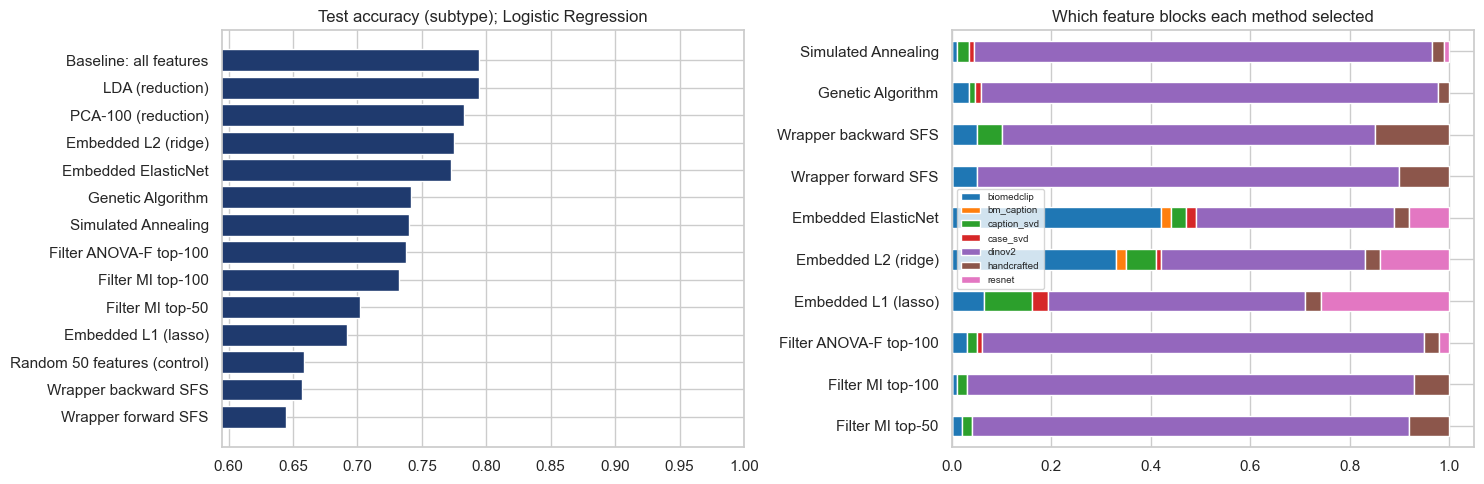

,method,n_features,test_accuracy,test_macro_F1,selection_time_s
0,Baseline: all features,5878,0.7944,0.7841,0.0
12,LDA (reduction),26,0.7942,0.7809,1.0
11,PCA-100 (reduction),100,0.7829,0.7680,1.5
5,Embedded L2 (ridge),100,0.7750,0.7571,38.5
6,Embedded ElasticNet,100,0.7724,0.7531,87.7
9,Genetic Algorithm,86,0.7414,0.7194,108.8
10,Simulated Annealing,89,0.7400,0.7194,100.9
3,Filter ANOVA-F top-100,100,0.7377,0.7165,65.4
2,Filter MI top-100,100,0.7319,0.7103,65.4
1,Filter MI top-50,50,0.7020,0.6739,65.4


In [17]:
for nm, Z, kdim in [("PCA-100 (reduction)", Zp, 100), ("LDA (reduction)", Zl, Zl.shape[1])]:
    kk = min(kdim, Z.shape[1]); sc_ = StandardScaler().fit(Z[train][:, :kk]); t0 = time.time(); clf = LogisticRegression(max_iter=300).fit(sc_.transform(Z[train][:, :kk]), y[train]); p = clf.predict(sc_.transform(Z[test][:, :kk]))
    results.append([nm, kk, round(accuracy_score(y[test], p), 4), round(f1_score(y[test], p, average="macro"), 4), round(time.time() - t0, 1)])
rnd = np.random.RandomState(SEED).choice(Xs.shape[1], 50, replace=False); acc, f1, _ = final_eval(rnd); results.append(["Random 50 features (control)", 50, round(acc, 4), round(f1, 4), 0.0])
res_all = pd.DataFrame(results, columns=["method", "n_features", "test_accuracy", "test_macro_F1", "selection_time_s"]).sort_values("test_accuracy", ascending=False)
res_all.to_csv(os.path.join(RES, "feature_selection_comparison.csv"), index=False)
fig, ax = plt.subplots(1, 2, figsize=(15, 5)); r = res_all.iloc[::-1]
ax[0].barh(r.method, r.test_accuracy, color="#1F3A6E"); ax[0].set_title(f"Test accuracy ({TARGET}); Logistic Regression"); ax[0].set_xlim(max(0, r.test_accuracy.min() - 0.05), 1)
comp = pd.DataFrame({m_: pd.Series(block[idx_]).value_counts() for m_, idx_ in sel.items()}).fillna(0).T; comp = comp.div(comp.sum(1), axis=0)
comp.plot.barh(stacked=True, ax=ax[1], color=bpal[:comp.shape[1]]); ax[1].set_title("Which feature blocks each method selected"); ax[1].legend(fontsize=7)
savefig("17_selection_comparison.png"); res_all

## 7. Save outputs for Notebook 04

In [18]:
np.save(os.path.join(FEAT, "X_fused_std.npy"), Xs); np.save(os.path.join(FEAT, "X_pca100.npy"), Zp[:, :100].astype(np.float32)); np.save(os.path.join(FEAT, "X_lda.npy"), Zl.astype(np.float32))
json.dump({"names": names.tolist(), "block": block.tolist()}, open(os.path.join(FEAT, "fused_feature_names.json"), "w"))
json.dump({k: v for k, v in sel.items()}, open(os.path.join(RES, "selected_features.json"), "w"))
print("saved X_fused_std", Xs.shape, "| selected sets:", {k: len(v) for k, v in sel.items()})

saved X_fused_std (21988, 5878) | selected sets: {'Filter MI top-50': 50, 'Filter MI top-100': 100, 'Filter ANOVA-F top-100': 100, 'Embedded L1 (lasso)': 31, 'Embedded L2 (ridge)': 100, 'Embedded ElasticNet': 100, 'Wrapper forward SFS': 20, 'Wrapper backward SFS': 20, 'Genetic Algorithm': 86, 'Simulated Annealing': 89}
